# Étape 4 : entraînement des classifieurs sur Google Colab

Ce notebook entraîne les réseaux qui répondent à la question **« quel type d'avion ? »** (A1 à A20), à partir des **vignettes** : un carré découpé autour de chaque avion.

| Modèle | Rôle |
|---|---|
| `classifieur_resnet18` | **notre classifieur principal** : ResNet-18 pré-entraîné sur ImageNet (transfer learning) |
| `classifieur_resnet18_sans_pretrain` | le même réseau sans pré-entraînement, pour mesurer l'apport du transfer learning |
| `classifieur_smallcnn` | un petit CNN « maison » entraîné de zéro, pour observer l'overfitting |

La baseline (forêt aléatoire) a déjà été entraînée sur le PC : macro-F1 de 0,614 en validation. Ses résultats sont dans `runs/baseline_rf/`.

**Mode d'emploi :**
1. Vérifier que Colab utilise un GPU : menu **Exécution → Modifier le type d'exécution → GPU T4**.
2. Exécuter les cellules **une par une, dans l'ordre** (`Maj + Entrée`).
3. Les résultats arrivent directement sur le Drive, dans les mêmes dossiers que sur le PC : `runs/` pour les courbes, les rapports et les matrices de confusion, `models/` pour les poids.
4. À la fin : **Exécution → Déconnecter et supprimer l'environnement d'exécution**, pour ne plus consommer d'unités.

## 1. Vérifier le GPU

In [1]:
import torch

if torch.cuda.is_available():
    print("GPU disponible :", torch.cuda.get_device_name(0))
else:
    print("PAS DE GPU : menu Exécution > Modifier le type d'exécution > GPU T4, puis relancer")

GPU disponible : NVIDIA L4


## 2. Connecter Google Drive

Accepte l'autorisation d'accès au Drive.

La variable `AVIONS_OUTPUT_DIR` indique à nos scripts d'écrire leurs résultats (`runs/`, `models/`) **directement dans le projet sur le Drive**.

In [2]:
import os

from google.colab import drive

drive.mount("/content/drive")

DRIVE_DIR = "/content/drive/MyDrive/projet_avions"  # le projet, synchronisé depuis le PC
PROJET = "/content/projet_ia"  # copie de travail dans Colab (effacée à la fin de la session)
os.environ["AVIONS_OUTPUT_DIR"] = DRIVE_DIR

Mounted at /content/drive


## 3. Copier le projet sur le disque de Colab

On travaille sur une copie locale, bien plus rapide que le Drive pour lire des milliers de petites images. Cette étape prend 1 à 3 minutes.

In [3]:
import shutil

shutil.rmtree(PROJET, ignore_errors=True)
shutil.copytree(
    DRIVE_DIR,
    PROJET,
    ignore=shutil.ignore_patterns(
        "runs", "models", "yolo", "crops", "weights", ".ipynb_checkpoints"
    ),
)
os.environ["PYTHONPATH"] = f"{PROJET}/src"  # pour que les scripts trouvent notre code (src/avions)
os.chdir(PROJET)
!python -c "import avions; print('Projet prêt :', avions.__file__)"

Projet prêt : /content/projet_ia/src/avions/__init__.py


## 4. Générer les vignettes

C'est le même script que sur le PC : un carré de 2 × la boîte autour de chaque avion, en 256 × 256 pixels. On obtient 7 870 vignettes, réparties en train / validation / test selon notre découpage.

In [4]:
!python scripts/make_crops.py

Vignettes: 100% 1331/1331 [00:19<00:00, 69.79it/s]
7870 vignettes écrites dans /content/projet_ia/data/crops
split
train    6295
val       787
test      788


## 5. Choisir ce qu'on entraîne

Les trois réseaux, avec les réglages de `configs/`. Comptez environ 5 à 15 minutes chacun sur un GPU T4. Le classifieur principal vient en premier.

Si l'un d'eux est déjà terminé, retire-le de la liste.

In [5]:
from pathlib import Path

import yaml

CONFIGS = [
    "configs/classifieur_resnet18.yaml",
    "configs/classifieur_resnet18_sans_pretrain.yaml",
    "configs/classifieur_smallcnn.yaml",
]
WORKERS = min(8, os.cpu_count())  # processus qui chargent les vignettes, selon la machine Colab


def nom_du_modele(config):
    return yaml.safe_load(Path(config).read_text(encoding="utf-8"))["name"]

## 6. Lancer les entraînements

Pour chaque epoch, on affiche la loss (l'erreur) sur l'entraînement et la validation, puis l'accuracy et la **macro-F1** sur la validation.

Le meilleur modèle est enregistré au fur et à mesure dans `models/` sur le Drive. L'entraînement s'arrête tout seul quand la validation ne progresse plus (early stopping).

In [6]:
for config in CONFIGS:
    print(f"\n===== Entraînement : {nom_du_modele(config)} =====")
    !python scripts/train_classifier.py {config} workers={WORKERS}


===== Entraînement : classifieur_resnet18 =====
Entraînement de classifieur_resnet18 sur cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 209MB/s]
epoch   1 | loss entraînement 2.728 | loss validation 2.550 | accuracy 0.339 | macro-F1 0.243
epoch   2 | loss entraînement 2.244 | loss validation 2.250 | accuracy 0.484 | macro-F1 0.406
epoch   3 | loss entraînement 2.001 | loss validation 2.071 | accuracy 0.559 | macro-F1 0.451
epoch   4 | loss entraînement 1.097 | loss validation 0.918 | accuracy 0.939 | macro-F1 0.939
epoch   5 | loss entraînement 0.846 | loss validation 0.848 | accuracy 0.968 | macro-F1 0.957
epoch   6 | loss entraînement 0.788 | loss validation 0.814 | accuracy 0.961 | macro-F1 0.966
epoch   7 | loss entraînement 0.760 | loss validation 0.752 | accuracy 0.991 | macro-F1 0.986
epoch   8 | loss entraînement 0.742 | loss validation 0.808 | accuracy 0.9

## 7. Résultats

Pour chaque modèle, on affiche :
- sa meilleure macro-F1 en **validation** ;
- ses courbes d'apprentissage ;
- sa **matrice de confusion**. Pour chaque vraie classe (ligne), elle montre la part des vignettes prédites dans chaque classe (colonne). La diagonale correspond aux bonnes réponses.

Copie le tableau des scores pour Claude.

                            modèle  macro-F1  accuracy  meilleure epoch
                       baseline_rf     0.614     0.693              NaN
              classifieur_resnet18     0.996     0.996              9.0
classifieur_resnet18_sans_pretrain     0.973     0.973             29.0
              classifieur_smallcnn     0.690     0.751             20.0

===== classifieur_resnet18 =====


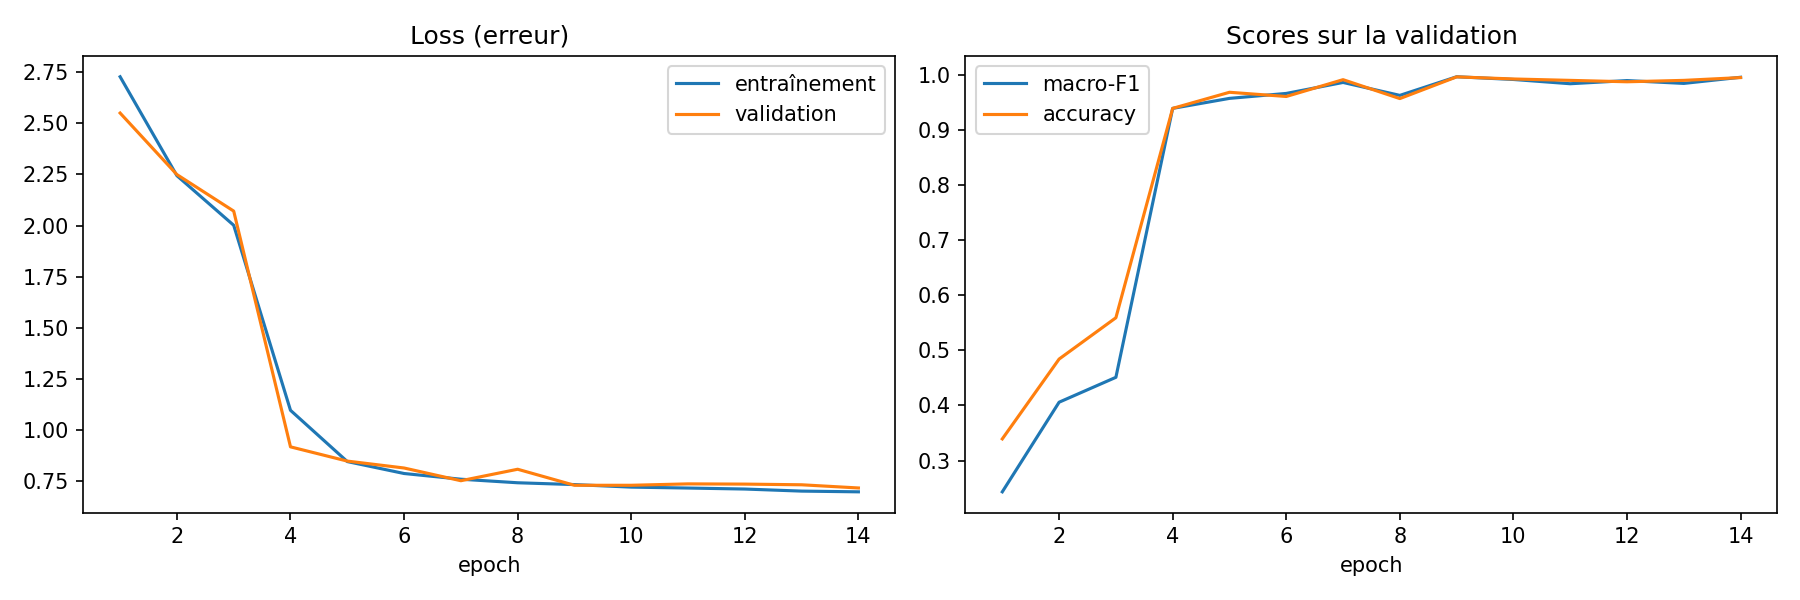

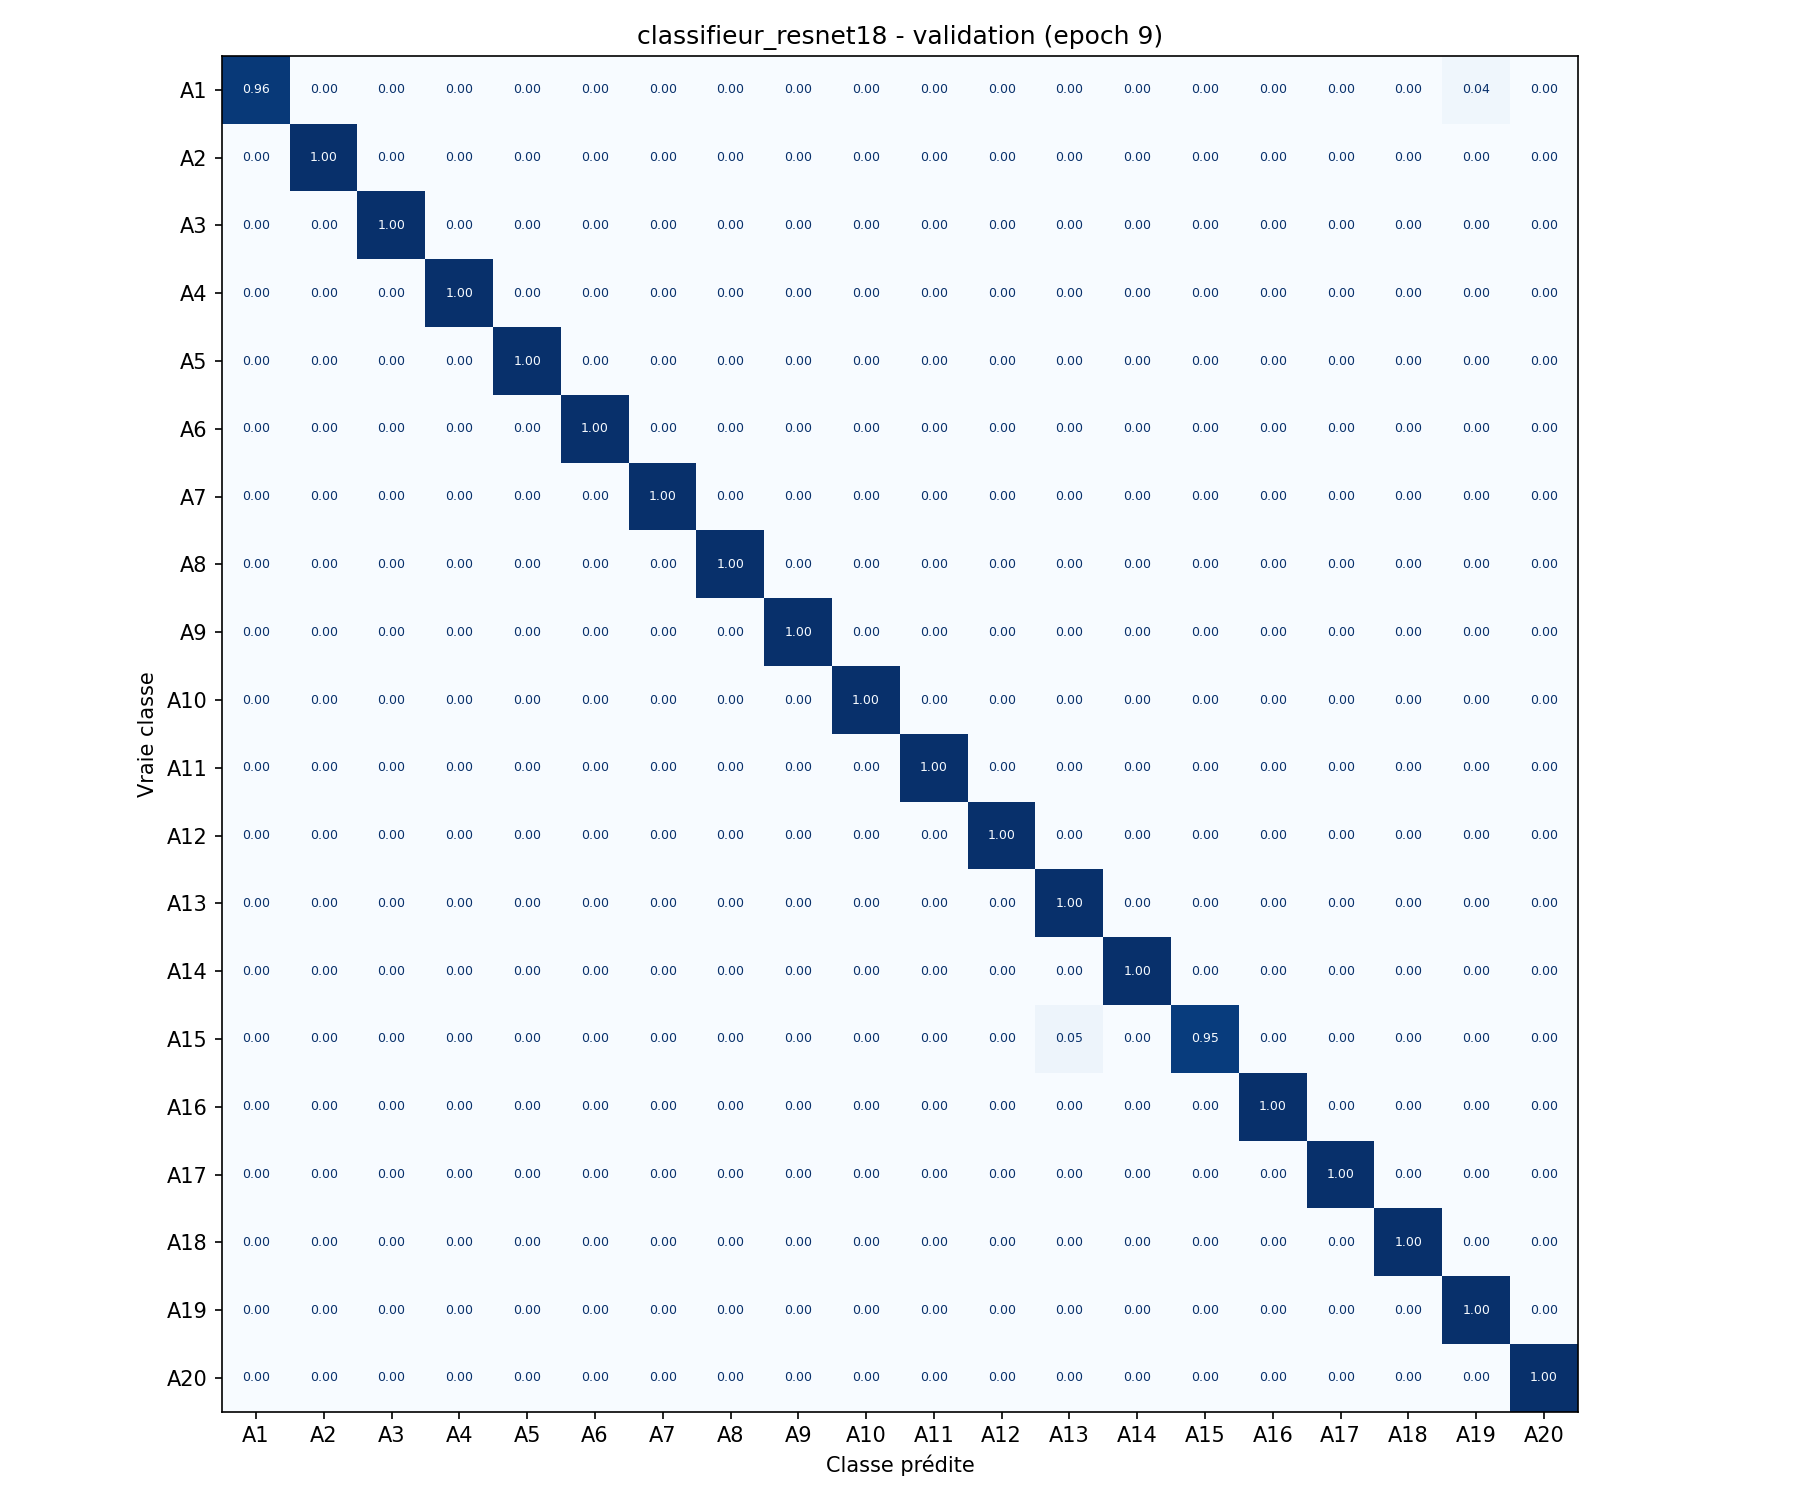


===== classifieur_resnet18_sans_pretrain =====


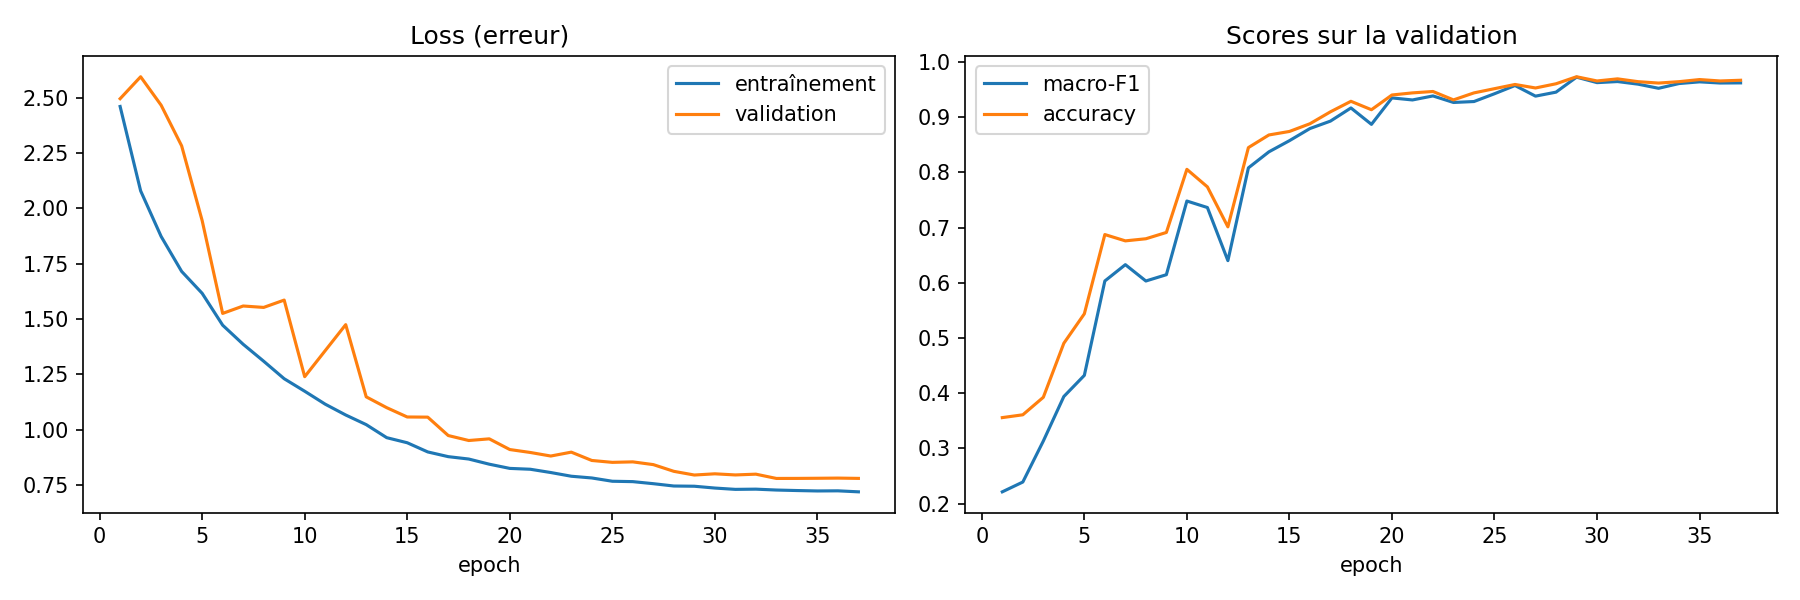

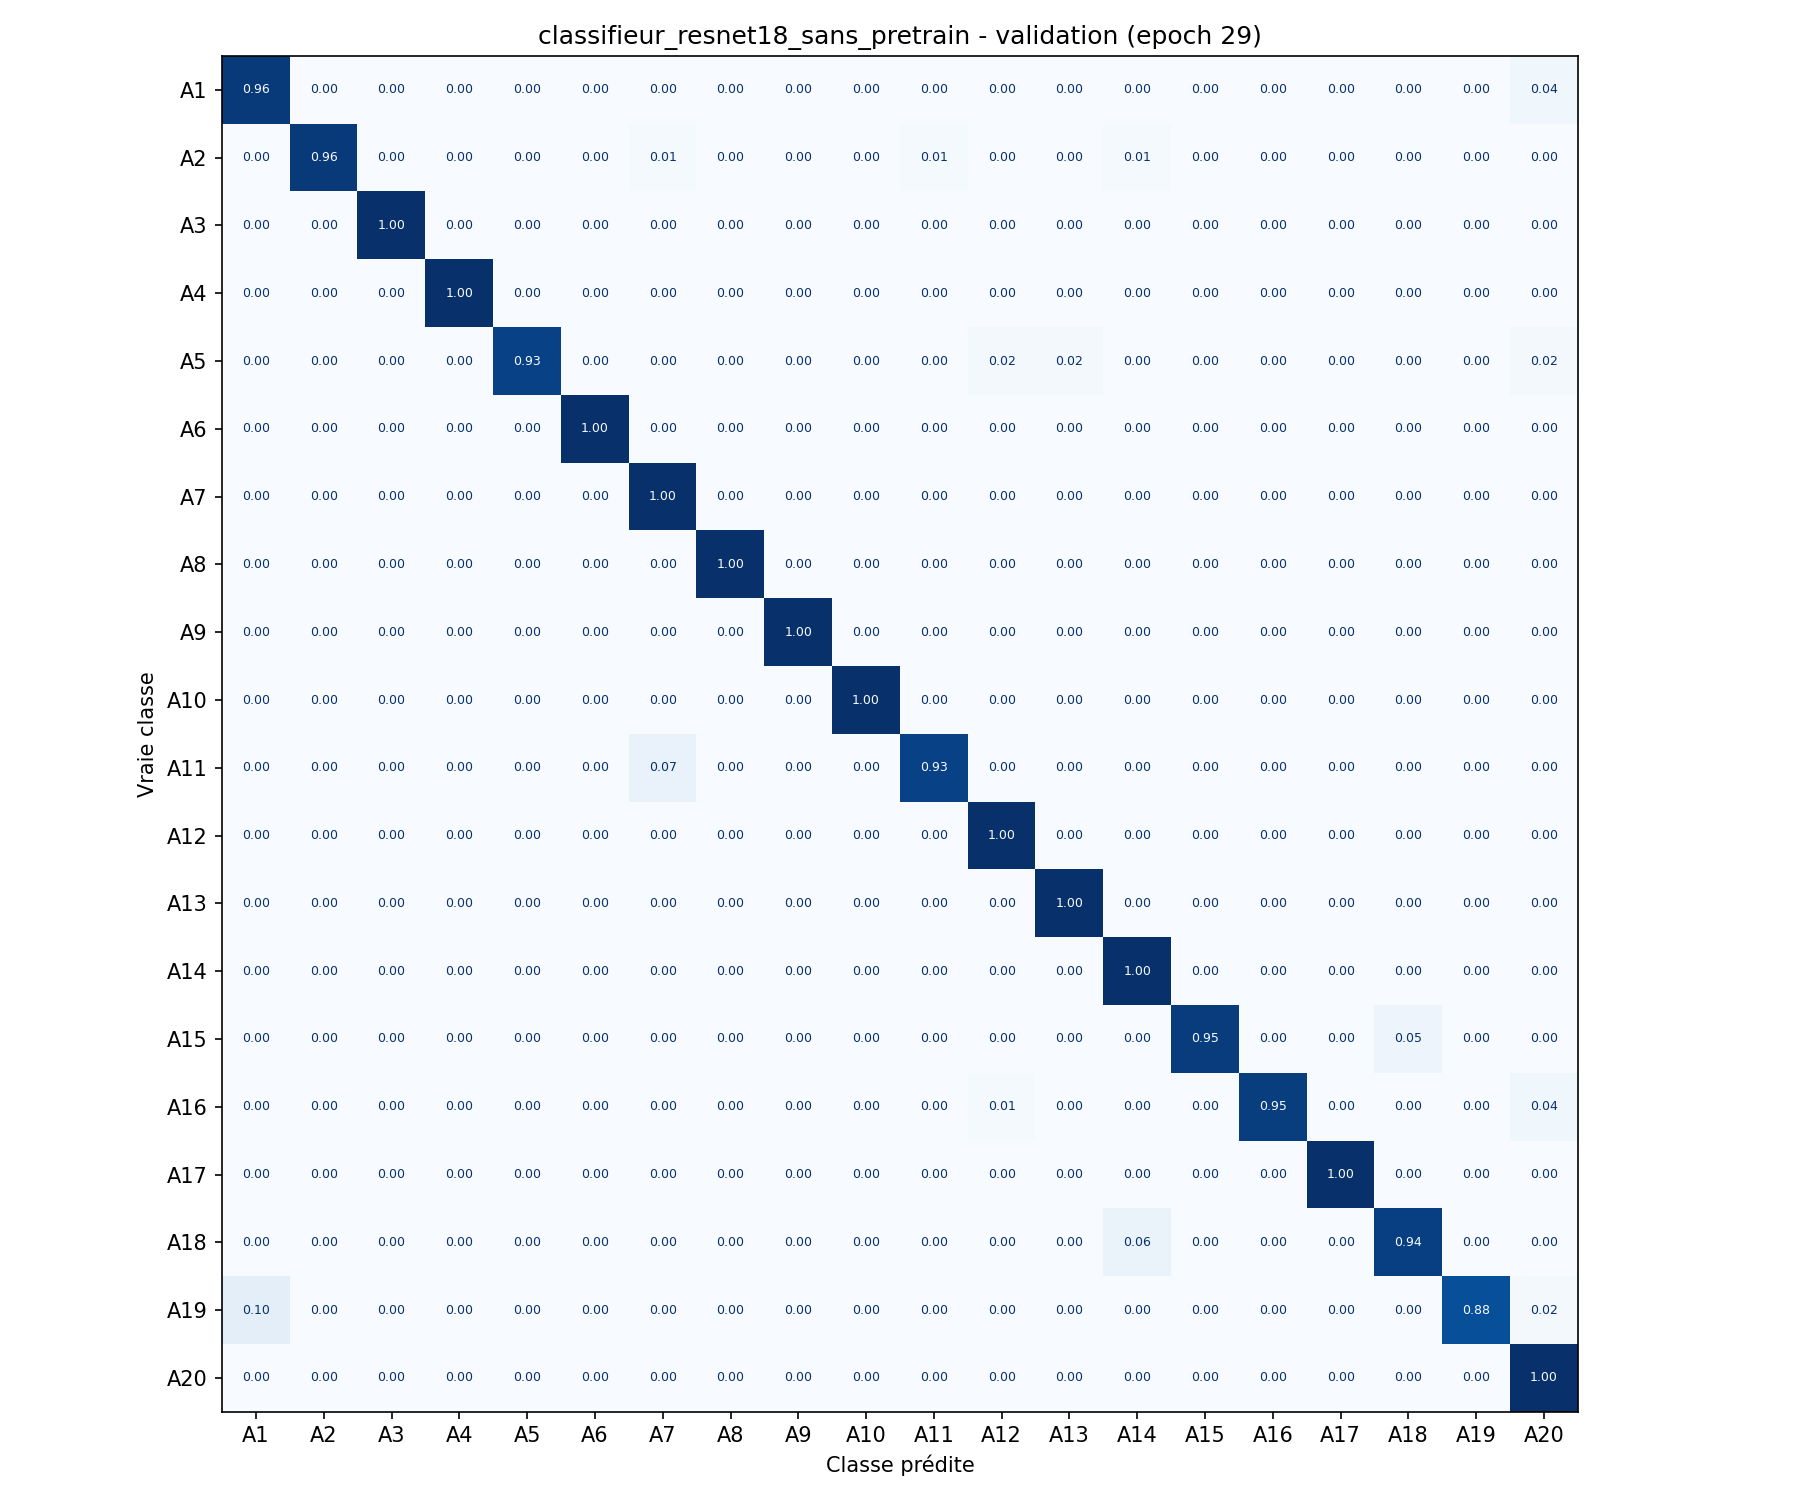


===== classifieur_smallcnn =====


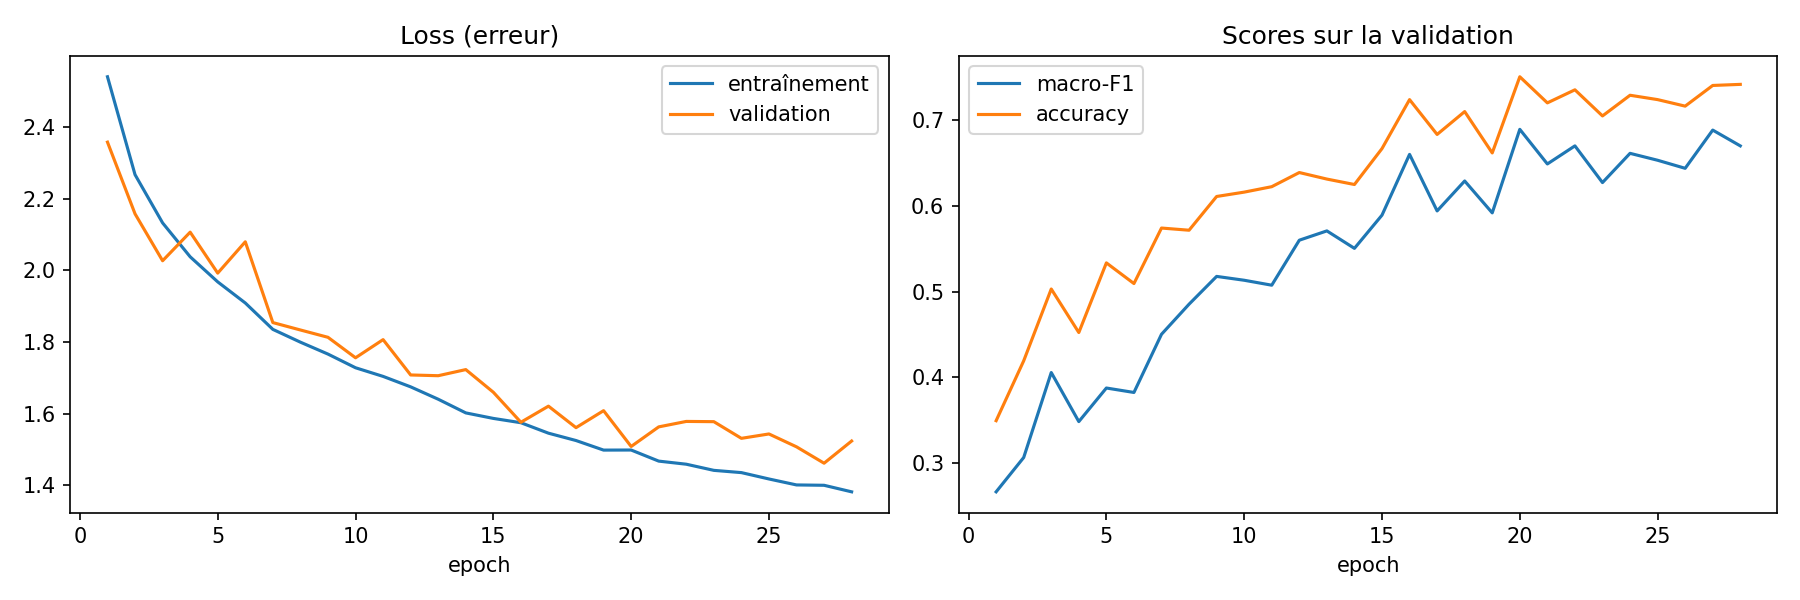

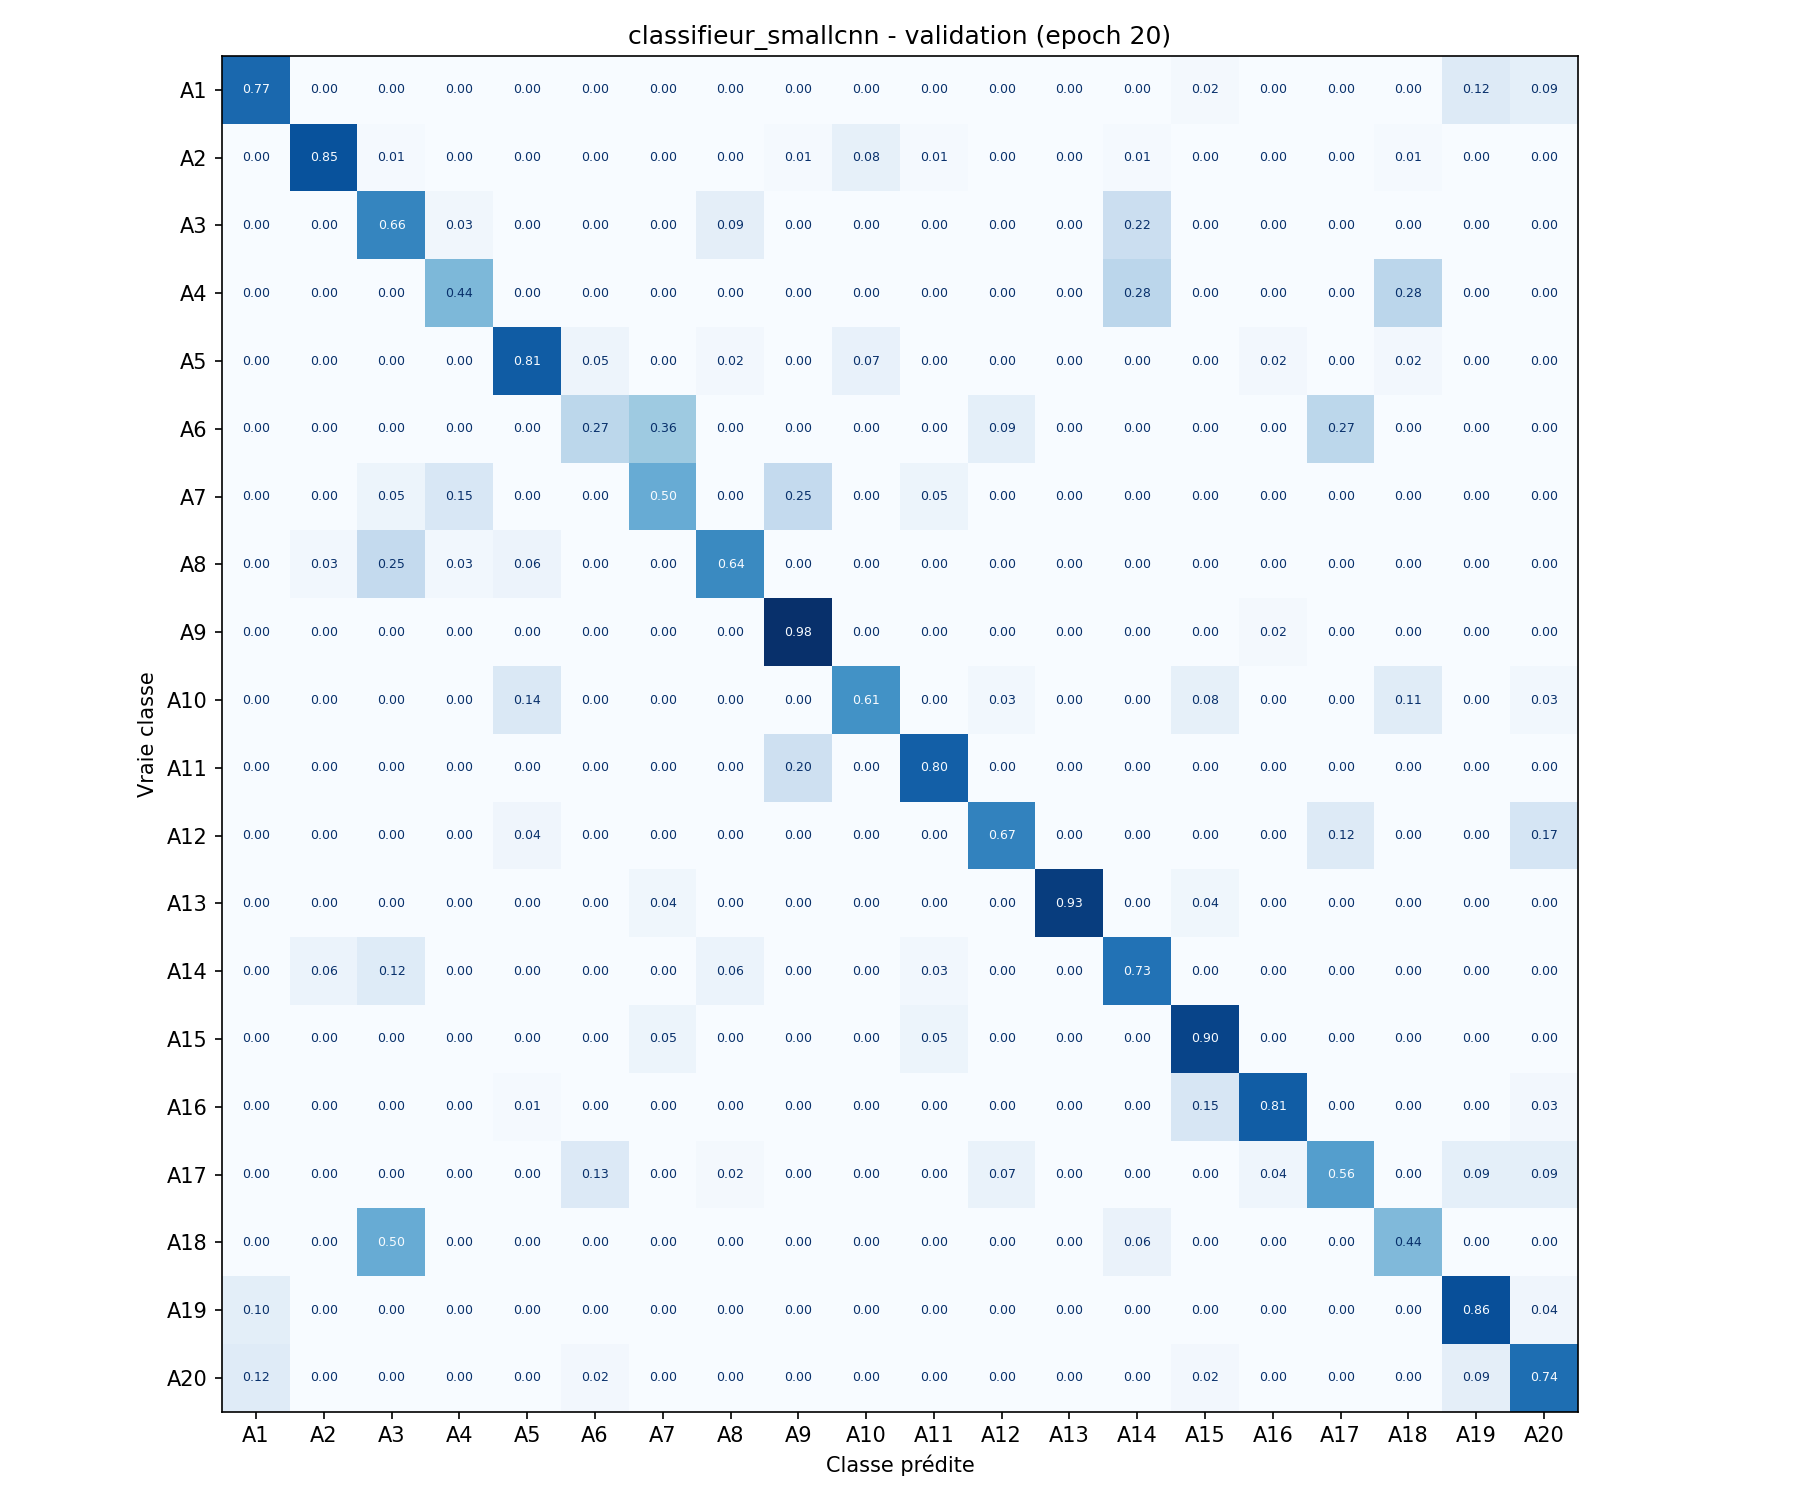

In [7]:
import json

import pandas as pd
from IPython.display import Image, display

lignes = []
baseline = Path(DRIVE_DIR) / "runs/baseline_rf/metrics.json"
if baseline.exists():
    val = json.loads(baseline.read_text())["val"]
    lignes.append(
        {"modèle": "baseline_rf", "macro-F1": val["macro_f1"], "accuracy": val["accuracy"]}
    )
for config in CONFIGS:
    nom = nom_du_modele(config)
    resultats = pd.read_csv(f"{DRIVE_DIR}/runs/{nom}/results.csv")
    best = resultats.loc[resultats["val_macro_f1"].idxmax()]
    lignes.append(
        {
            "modèle": nom,
            "macro-F1": best["val_macro_f1"],
            "accuracy": best["val_accuracy"],
            "meilleure epoch": int(best["epoch"]),
        }
    )
print(pd.DataFrame(lignes).round(3).to_string(index=False))

for config in CONFIGS:
    nom = nom_du_modele(config)
    print(f"\n===== {nom} =====")
    display(Image(f"{DRIVE_DIR}/runs/{nom}/results.png"))
    display(Image(f"{DRIVE_DIR}/runs/{nom}/confusion_matrix.png", width=700))

## 8. Terminer

Menu **Exécution → Déconnecter et supprimer l'environnement d'exécution**, pour ne plus consommer d'unités de calcul.

Ensuite, sur le PC, `uv run python scripts/sync_drive.py` ramène les modèles et les résultats dans le projet.